In [28]:
import sys
sys.path.append("backend/src")
import georeferencing as geo
from services import skraafoto
import matplotlib.pyplot as plt
from utils import image_handler
from PIL import Image
import folium 
from pyproj import Transformer
from geopy.distance import geodesic
import numpy as np
%load_ext autoreload
%autoreload 

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Calculating geolocation error for 1 point

We start by selecting a known location on Google Maps (latitude and longitude), then project it onto a Skraafoto image using the camera model and projection logic provided by Skraafoto. The resulting pixel coordinates are then converted back to geographic coordinates using a tile-specific homography matrix — our estimation logic. Finally, we compare the original and recovered coordinates to calculate the geolocation error, which is measured in meters using geodesic distance from the geopy library. This allows us to evaluate the accuracy of the system.

We test locations from three different cities: Horsens, Skanderborg, and Vejle. The location in Silkeborg was specifically chosen due to its known elevation variation, which is particularly interesting for evaluating the limitations of homography, as it assumes a flat surface.

Before these tests were conducted, the tile split for a Skrafoto image was defined by a 4x4 split, meaning one image would consists of 16 local homogprahies. The tests revealed that for elevated areas, this split was still insufficient. Therefore, the final tile split selected is 5x5, meaing each Skrafoto image contains of 25 local homographies. 

## Item 1 - Horsens 

In [2]:
stac_item_id = "2023_82_23_2_0012_00001362" # Horsens, train station 
item = skraafoto.fetch_skraafoto_item(stac_item_id)
item

{'type': 'Feature',
 'stac_version': '1.0.0',
 'stac_extensions': ['https://stac-extensions.github.io/view/v1.0.0/schema.json',
  'https://stac-extensions.github.io/projection/v1.0.0/schema.json',
  'https://raw.githubusercontent.com/stac-extensions/perspective-imagery/main/json-schema/schema.json'],
 'id': '2023_82_23_2_0012_00001362',
 'collection': 'skraafotos2023',
 'geometry': {'type': 'Polygon',
  'coordinates': [[[9.828368773330094, 55.8696539661694],
    [9.853499831474384, 55.869338962728],
    [9.849764311824739, 55.85661670314353],
    [9.831549785620979, 55.85675351843603],
    [9.828368773330094, 55.8696539661694]]]},
 'bbox': [9.828368773330094,
  55.85661670314353,
  9.853499831474384,
  55.8696539661694],
 'properties': {'datetime': '2023-04-08T13:44:42Z',
  'gsd': 0.09,
  'license': 'various',
  'platform': 'Fixed-wing aircraft',
  'instruments': ['Osprey-434S42218X318205-f120_Rev01.00_C114'],
  'providers': [{'name': 'field', 'roles': ['producer']},
   {'url': 'https:

In [3]:
img= image_handler.convert_img_to_byte_array(image_handler.extract_selected_image(item))

/Users/kristinajassova/Library/Caches/pypoetry/virtualenvs/bachelor-project-OC8LGAW5-py3.11/lib/python3.11/site-packages/PIL/Image.py:3402: DecompressionBombWarning: Image size (149360640 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


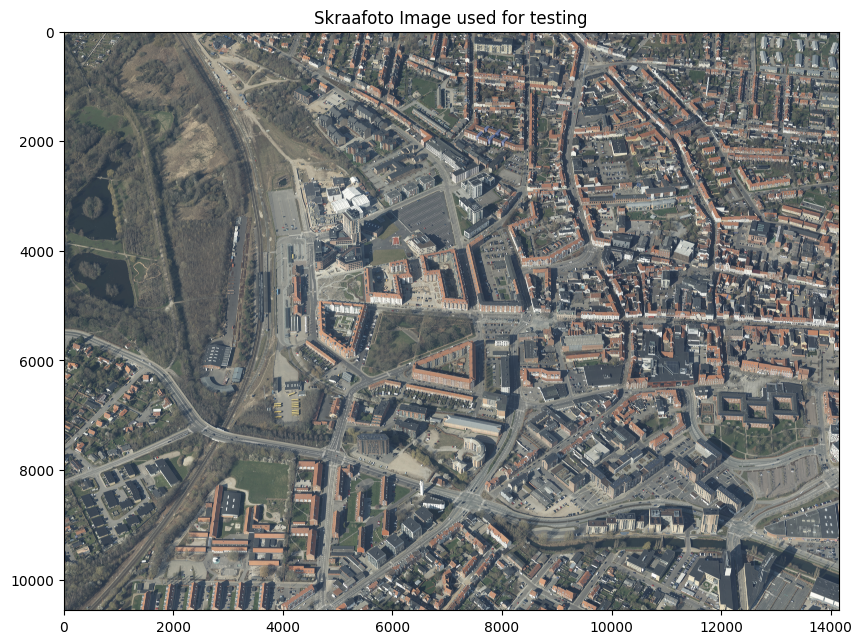

In [4]:
plt.figure(figsize=(10, 10))
plt.imshow(img)
plt.title("Skraafoto Image used for testing")
plt.show()

### Location 1 - VIA Campus Horsens

In [183]:
# VIA campus Horsens location from Google Maps 55.86333752937521, 9.837184924674709

longitude = 9.837184924674709
latitude = 55.86333752937521
img_height, img_width = item['properties']['proj:shape'][:2]

transformer = Transformer.from_crs("EPSG:4326", f"EPSG:{item['properties']['pers:crs']}", always_xy=True)
KRT = geo.precompute_projection_params(item)

pixel_x, pixel_y = geo.latlon_to_pixel(latitude, longitude, transformer, KRT)
print(f"Project point X: {pixel_x}")
print(f"Project point Y: {pixel_y}")

Project point X: 4719.184095742459
Project point Y: 6248.840624529407


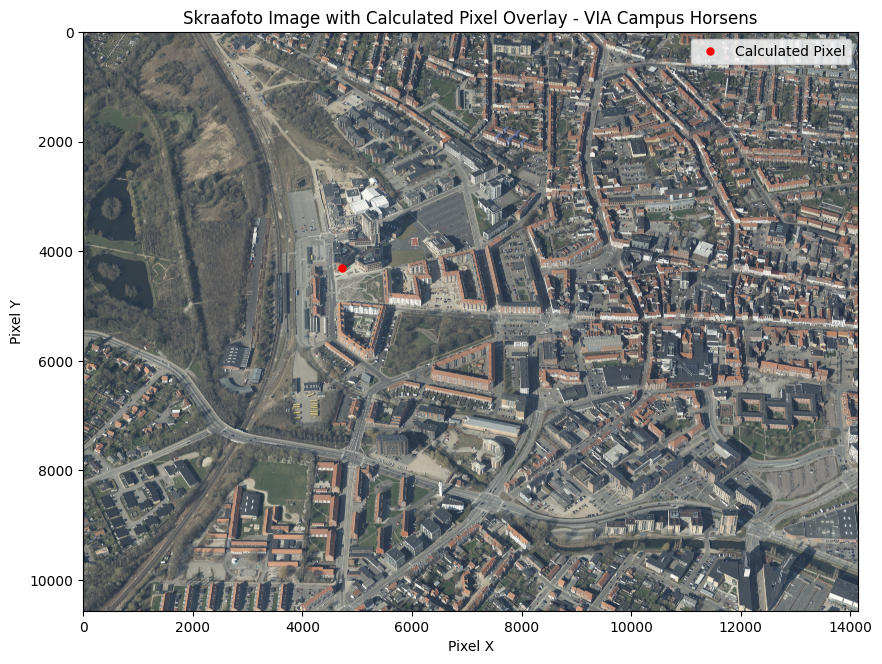

In [150]:
plt.figure(figsize=(10, 10))
plt.imshow(img)

pixel_x = pixel_x  
pixel_y_flipped = img_height - pixel_y  

plt.plot(pixel_x, pixel_y_flipped, 'ro', markersize=5, label='Calculated Pixel')
plt.legend()
plt.title("Skraafoto Image with Calculated Pixel Overlay - VIA Campus Horsens")
plt.xlabel("Pixel X")
plt.ylabel("Pixel Y")
plt.show()

In [151]:
true_coord = (latitude, longitude)
tile = geo.get_tile_for_pixel(pixel_x, pixel_y, stac_item_id)
X_world, Y_world = geo.convert_pixel_to_world_homography(pixel_x, pixel_y, tile['homography'])

Tiles belonging to STAC item ID 2023_82_23_2_0012_00001362 loaded from storage.
Bounding Box in Pixels: x_min=0, x_max=2748, y_min=0, y_max=3303
Checking if (4719.184095742459, 6248.840624529407) falls inside...

Bounding Box in Pixels: x_min=2392, x_max=7289, y_min=0, y_max=3303
Checking if (4719.184095742459, 6248.840624529407) falls inside...

Bounding Box in Pixels: x_min=7099, x_max=11239, y_min=6109, y_max=8676
Checking if (4719.184095742459, 6248.840624529407) falls inside...

Bounding Box in Pixels: x_min=10889, x_max=14144, y_min=6175, y_max=8787
Checking if (4719.184095742459, 6248.840624529407) falls inside...

Bounding Box in Pixels: x_min=0, x_max=3530, y_min=8457, y_max=10560
Checking if (4719.184095742459, 6248.840624529407) falls inside...

Bounding Box in Pixels: x_min=3313, x_max=7099, y_min=8483, y_max=10560
Checking if (4719.184095742459, 6248.840624529407) falls inside...

Bounding Box in Pixels: x_min=7053, x_max=10889, y_min=8528, y_max=10560
Checking if (4719.18

In [152]:
print(f"Estimated latitude: {Y_world}")
print(f"Estimated longitude: {X_world}")
print(f"Actual latitude (from Google Maps): {latitude}")
print(f"Actual longitude (from Google Maps): {longitude}")

Estimated latitude: 55.86333467803882
Estimated longitude: 9.837188399845504
Actual latitude (from Google Maps): 55.86333752937521
Actual longitude (from Google Maps): 9.837184924674709


#### Calculate difference in meters between actual vs. estimated coordinates

In [153]:
error_meters = geodesic(true_coord, (Y_world, X_world)).meters
print(f"Geolocation error: {error_meters:.2f} meters")

Geolocation error: 0.38 meters


## Item 2 - Skanderborg - area with more significant elevation differences

In [109]:
stac_item_id_2 = "2023_82_24_2_0001_00001802"
item_2 = skraafoto.fetch_skraafoto_item(stac_item_id_2)
item_2

{'type': 'Feature',
 'stac_version': '1.0.0',
 'stac_extensions': ['https://stac-extensions.github.io/view/v1.0.0/schema.json',
  'https://stac-extensions.github.io/projection/v1.0.0/schema.json',
  'https://raw.githubusercontent.com/stac-extensions/perspective-imagery/main/json-schema/schema.json'],
 'id': '2023_82_24_2_0001_00001802',
 'collection': 'skraafotos2023',
 'geometry': {'type': 'Polygon',
  'coordinates': [[[9.986674068019424, 56.0216820640743],
    [10.010763210983594, 56.021160322989076],
    [10.007059844658887, 56.00913843886376],
    [9.989436437037604, 56.00948882263195],
    [9.986674068019424, 56.0216820640743]]]},
 'bbox': [9.986674068019424,
  56.00913843886376,
  10.010763210983594,
  56.0216820640743],
 'properties': {'datetime': '2023-04-18T16:17:52Z',
  'gsd': 0.09,
  'license': 'various',
  'platform': 'Fixed-wing aircraft',
  'instruments': ['Osprey-434S42218X318205-f120_Rev01.00_C114'],
  'providers': [{'name': 'field', 'roles': ['producer']},
   {'url': '

### Test location 2 

In [169]:
img_2= image_handler.convert_img_to_byte_array(image_handler.extract_selected_image(item_2))

/Users/kristinajassova/Library/Caches/pypoetry/virtualenvs/bachelor-project-OC8LGAW5-py3.11/lib/python3.11/site-packages/PIL/Image.py:3402: DecompressionBombWarning: Image size (149360640 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


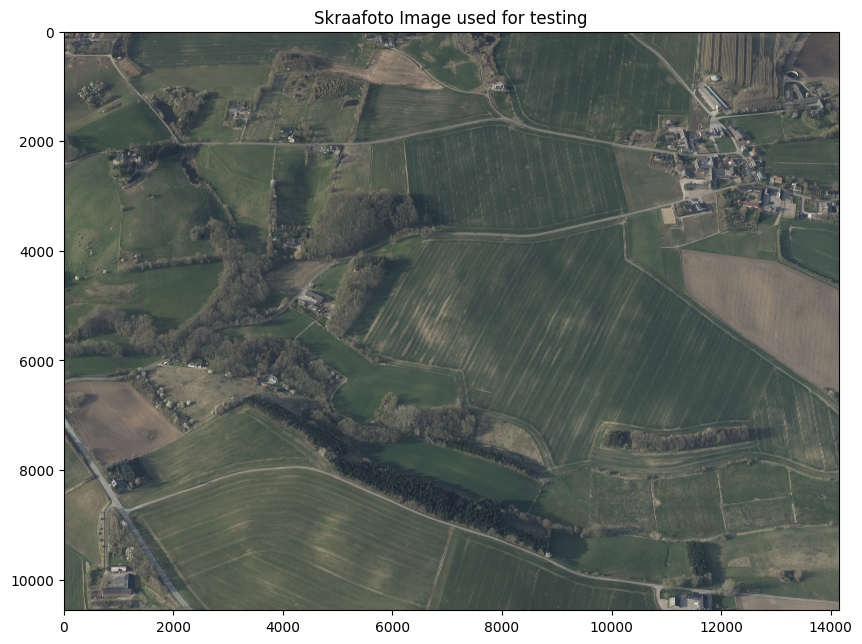

In [170]:
plt.figure(figsize=(10, 10))
plt.imshow(img_2)
plt.title("Skraafoto Image used for testing")
plt.show()

In [ ]:
longitude = 9.995205712259763
latitude = 56.01589340732025
img_height, img_width = item_2['properties']['proj:shape'][:2]

transformer = Transformer.from_crs("EPSG:4326", f"EPSG:{item_2['properties']['pers:crs']}", always_xy=True)
KRT = geo.precompute_projection_params(item_2)

pixel_x, pixel_y = geo.latlon_to_pixel(latitude, longitude, transformer, KRT)
print(f"Project point X: {pixel_x}")
print(f"Project point Y: {pixel_y}")


Project point X: 4845.000542738502
Project point Y: 6320.166323977715


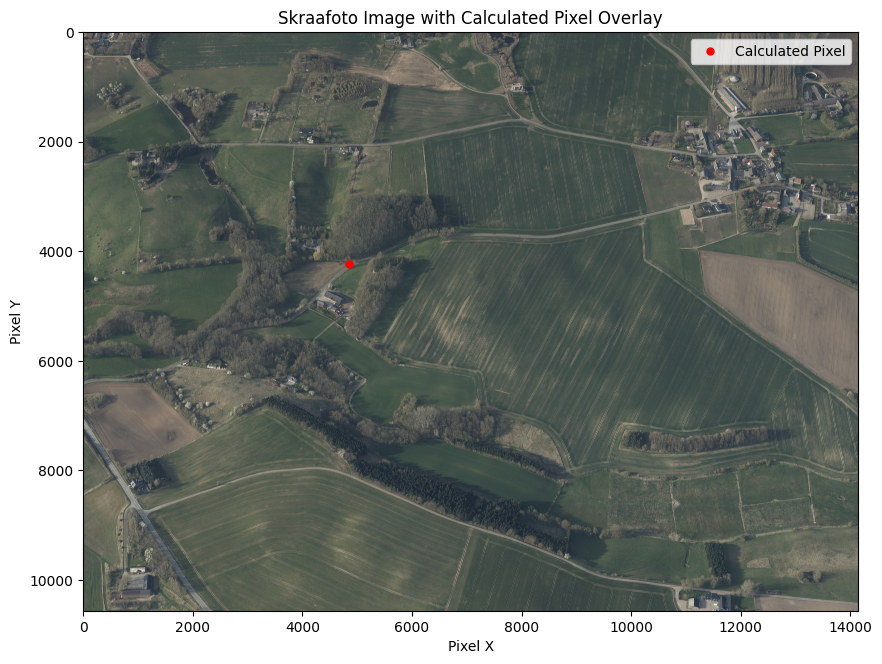

In [188]:
plt.figure(figsize=(10, 10))
plt.imshow(img_2)

pixel_x = pixel_x  
pixel_y_flipped = img_height - pixel_y  

plt.plot(pixel_x, pixel_y_flipped, 'ro', markersize=5, label='Calculated Pixel')
plt.legend()
plt.title("Skraafoto Image with Calculated Pixel Overlay")
plt.xlabel("Pixel X")
plt.ylabel("Pixel Y")
plt.show()

In [189]:
true_coord = (latitude, longitude)
tile = geo.get_tile_for_pixel(pixel_x, pixel_y, stac_item_id_2)
X_world, Y_world = geo.convert_pixel_to_world_homography(pixel_x, pixel_y, tile['homography'])

Tiles belonging to STAC item ID 2023_82_24_2_0001_00001802 loaded from storage.
Bounding Box in Pixels: x_min=0, x_max=1937, y_min=0, y_max=2284
Checking if (4845.000542738502, 6320.166323977715) falls inside...

Bounding Box in Pixels: x_min=1637, x_max=5524, y_min=0, y_max=2441
Checking if (4845.000542738502, 6320.166323977715) falls inside...

Bounding Box in Pixels: x_min=0, x_max=2419, y_min=4561, y_max=7039
Checking if (4845.000542738502, 6320.166323977715) falls inside...

Bounding Box in Pixels: x_min=2220, x_max=5581, y_min=4638, y_max=7116
Checking if (4845.000542738502, 6320.166323977715) falls inside...



In [190]:
print(f"Estimated latitude: {Y_world}")
print(f"Estimated longitude: {X_world}")
print(f"Actual latitude (from Google Maps): {latitude}")
print(f"Actual longitude (from Google Maps): {longitude}")

Estimated latitude: 56.01586006318698
Estimated longitude: 9.995200250844805
Actual latitude (from Google Maps): 56.01589340732025
Actual longitude (from Google Maps): 9.995205712259763


In [ ]:
error_meters = geodesic(true_coord, (Y_world, X_world)).meters
print(f"Geolocation error: {error_meters:.2f} meters")

# with 16 homographies per image, the error was 6.9 meters, we increased to 25 and the below is the result

Geolocation error: 3.73 meters


In [191]:
midpoint = [(latitude + Y_world)/2, (longitude + X_world)/2]
m = folium.Map(location=midpoint, zoom_start=40)
folium.Marker(location=true_coord, popup="True Location", icon=folium.Icon(color='green')).add_to(m)
folium.Marker(location=(Y_world, X_world), popup="Estimated Location", icon=folium.Icon(color='red')).add_to(m)

folium.PolyLine([true_coord, (Y_world, X_world)], color="blue", weight=2.5).add_to(m)

m.save("geolocation_error_silkeborg.html")

## Item 3 - Vejle

In [171]:
stac_item_id_3 = "2023_83_29_2_0020_00000674"
item_3 = skraafoto.fetch_skraafoto_item(stac_item_id_3)

In [172]:
img_3= image_handler.convert_img_to_byte_array(image_handler.extract_selected_image(item_3))

/Users/kristinajassova/Library/Caches/pypoetry/virtualenvs/bachelor-project-OC8LGAW5-py3.11/lib/python3.11/site-packages/PIL/Image.py:3402: DecompressionBombWarning: Image size (98275296 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


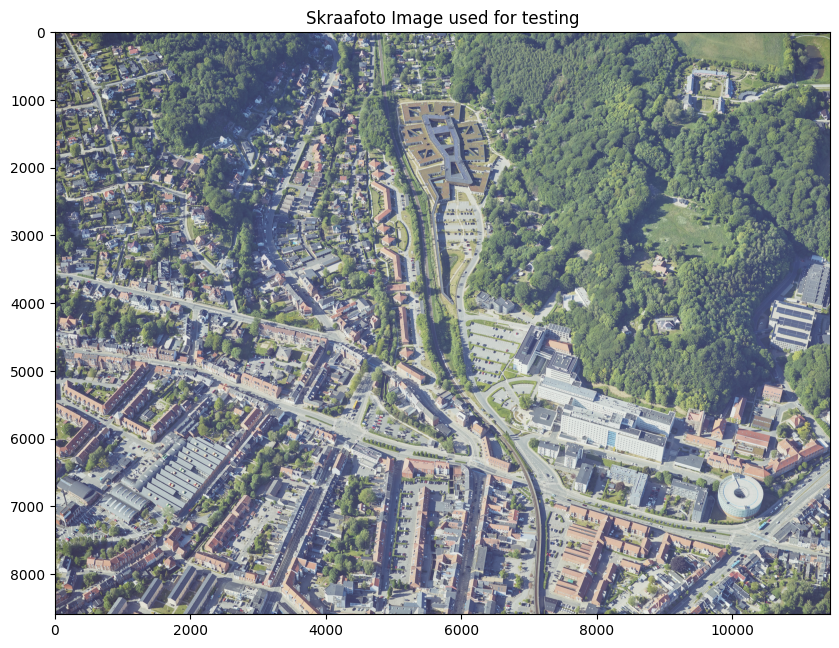

In [173]:
plt.figure(figsize=(10, 10))
plt.imshow(img_3)
plt.title("Skraafoto Image used for testing")
plt.show()

In [174]:
## 55.717422195622085, 9.529599605484709
latitude = 55.717422195622085
longitude = 9.529599605484709

img_height, img_width = item_3['properties']['proj:shape'][:2]

transformer = Transformer.from_crs("EPSG:4326", f"EPSG:{item_3['properties']['pers:crs']}", always_xy=True)
KRT = geo.precompute_projection_params(item_3)

pixel_x, pixel_y = geo.latlon_to_pixel(latitude, longitude, transformer, KRT)
print(f"Project point X: {pixel_x}")
print(f"Project point Y: {pixel_y}")

Project point X: 1084.495723306885
Project point Y: 5566.992287974964


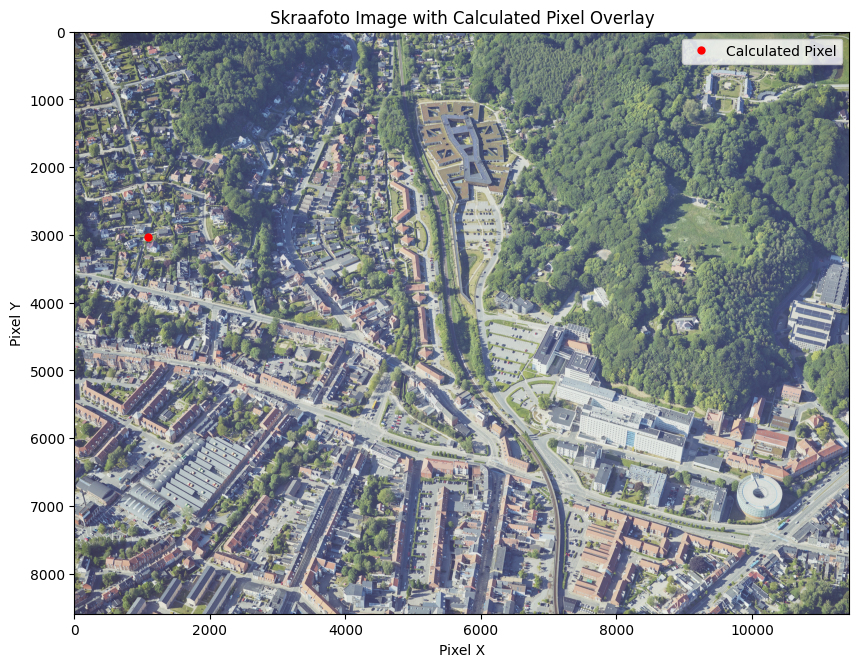

In [176]:
plt.figure(figsize=(10, 10))
plt.imshow(img_3)

pixel_x = pixel_x  
pixel_y_flipped = img_height - pixel_y  

plt.plot(pixel_x, pixel_y_flipped, 'ro', markersize=5, label='Calculated Pixel')
plt.legend()
plt.title("Skraafoto Image with Calculated Pixel Overlay")
plt.xlabel("Pixel X")
plt.ylabel("Pixel Y")
plt.show()

In [177]:
true_coord = (latitude, longitude)
tile = geo.get_tile_for_pixel(pixel_x, pixel_y, stac_item_id_3)
X_world, Y_world = geo.convert_pixel_to_world_homography(pixel_x, pixel_y, tile['homography'])

Error while loading /Users/kristinajassova/Code/bachelor_project/backend/data/tile_data.h5: ID '2023_83_29_2_0020_00000674' not found in the HDF5 file.
Skraafoto image with the given ID has not been processed yet.
Starting image tiling..
Saving group: 2023_83_29_2_0020_00000674
Appending group: 2023_83_29_2_0020_00000674
Data successfully appended to 'tile_data'
Bounding Box in Pixels: x_min=0, x_max=1332, y_min=0, y_max=2223
Checking if (1084.495723306885, 5566.992287974964) falls inside...

Bounding Box in Pixels: x_min=982, x_max=4348, y_min=0, y_max=2241
Checking if (1084.495723306885, 5566.992287974964) falls inside...

Bounding Box in Pixels: x_min=4257, x_max=7524, y_min=0, y_max=2259
Checking if (1084.495723306885, 5566.992287974964) falls inside...

Bounding Box in Pixels: x_min=7357, x_max=10782, y_min=0, y_max=2325
Checking if (1084.495723306885, 5566.992287974964) falls inside...

Bounding Box in Pixels: x_min=10371, x_max=11438, y_min=0, y_max=2338
Checking if (1084.495723

In [178]:
print(f"Estimated latitude: {Y_world}")
print(f"Estimated longitude: {X_world}")
print(f"Actual latitude (from Google Maps): {latitude}")
print(f"Actual longitude (from Google Maps): {longitude}")

Estimated latitude: 55.71741870349514
Estimated longitude: 9.529596174149093
Actual latitude (from Google Maps): 55.717422195622085
Actual longitude (from Google Maps): 9.529599605484709


In [179]:
error_meters = geodesic(true_coord, (Y_world, X_world)).meters
print(f"Geolocation error: {error_meters:.2f} meters")

Geolocation error: 0.44 meters


# Calculating geolocation error for a grid of points

The following code applies the same strategy for testing as described above. However, we do this for a grid of geographic coordinates covered in two areas/items - one for Horsens and one for Skanderborg. 

We do a 8x8 grid and then calculate a mean error to test the accuracy of the homography-based model. 

These tests are conducted on the tile split (5x5 -> 25 homographies)

## Horsens - relatively flat surface

In [33]:
stac_item_id = "2023_82_23_2_0012_00001362" # Horsens, train station 
item_horsens = skraafoto.fetch_skraafoto_item(stac_item_id)

lon_min, lat_min, lon_max, lat_max = item_horsens['bbox'] 
img_height, img_width = item_horsens['properties']['proj:shape'][:2]
num_lat = 8
num_lon = 8

lat_vals = np.linspace(lat_min, lat_max, num_lat)
lon_vals = np.linspace(lon_min, lon_max, num_lon)

grid_points = [(lat, lon) for lat in lat_vals for lon in lon_vals]
transformer = Transformer.from_crs("EPSG:4326", f"EPSG:{item_horsens['properties']['pers:crs']}", always_xy=True)
KRT = geo.precompute_projection_params(item_horsens)

errors = []
for lat, lon in grid_points:
    pixel_x, pixel_y = geo.latlon_to_pixel(lat, lon, transformer, KRT)
    if not (0 <= pixel_x < img_width and 0 <= pixel_y < img_height):
        continue
    tile = geo.get_tile_for_pixel(pixel_x, pixel_y, stac_item_id)
    est_lon, est_lat = geo.convert_pixel_to_world_homography(pixel_x, pixel_y, tile['homography'])
    error = geodesic((lat, lon), (est_lat, est_lon)).meters
    errors.append(error)
errors

Tiles belonging to STAC item ID 2023_82_23_2_0012_00001362 loaded from storage.
Bounding Box in Pixels: x_min=0, x_max=1779, y_min=0, y_max=2619
Checking if (616.2397445289821, 1872.98838012134) falls inside...

Tiles belonging to STAC item ID 2023_82_23_2_0012_00001362 loaded from storage.
Bounding Box in Pixels: x_min=0, x_max=1779, y_min=0, y_max=2619
Checking if (3274.4934618964726, 1871.6147425791455) falls inside...

Bounding Box in Pixels: x_min=1408, x_max=5414, y_min=0, y_max=2644
Checking if (3274.4934618964726, 1871.6147425791455) falls inside...

Tiles belonging to STAC item ID 2023_82_23_2_0012_00001362 loaded from storage.
Bounding Box in Pixels: x_min=0, x_max=1779, y_min=0, y_max=2619
Checking if (5922.384230779584, 1898.889872009131) falls inside...

Bounding Box in Pixels: x_min=1408, x_max=5414, y_min=0, y_max=2644
Checking if (5922.384230779584, 1898.889872009131) falls inside...

Bounding Box in Pixels: x_min=0, x_max=2373, y_min=4983, y_max=7063
Checking if (5922.

[0.12463978647975446,
 0.9094877316040328,
 0.28583642047915914,
 0.20812609822454536,
 0.355190013051449,
 0.15853060382874257,
 0.3280191322757864,
 0.5497287410928802,
 0.36886645187991063,
 0.20194129016595522,
 0.4460369425869716,
 0.27156068674694406,
 0.9943807329168077,
 0.8145613542114667,
 0.10624365253424382,
 0.046725723811690344,
 0.7344628607114553,
 1.2226619041013693,
 0.44836364174046023,
 0.6965776840943393,
 0.16107353608265323,
 0.15838995676039858,
 0.9946545973012395,
 1.7249596833954108,
 0.5627706184922369,
 0.7850357665144756,
 0.6316521071238397,
 0.3557034555420204,
 2.4099453975592633,
 0.3417288939422296,
 0.8733410296359486,
 2.965577080104649,
 0.2839245116801122,
 0.33388169730360445,
 0.30898986071908785,
 0.31057083477481506,
 0.9145114788643111,
 1.5118311282452632]

### Results

In [34]:
print("Number of reference points", len(errors))
print("Min:", np.min(errors))
print("Max:", np.max(errors))
print("Mean:", np.mean(errors))
print("Median:", np.median(errors))
print("Std Dev:", np.std(errors))
print("25th percentile:", np.percentile(errors, 25))
print("75th percentile:", np.percentile(errors, 75))

Number of reference points 38
Min: 0.046725723811690344
Max: 2.965577080104649
Mean: 0.655275870699461
Median: 0.4074516972334411
Std Dev: 0.6179412736550937
25th percentile: 0.2844024888798739
75th percentile: 0.8586461107798281


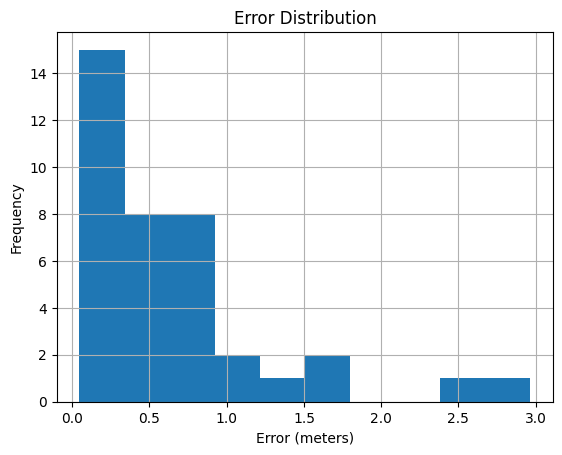

In [35]:
plt.hist(errors, bins=10)
plt.title("Error Distribution")
plt.xlabel("Error (meters)")
plt.ylabel("Frequency")
plt.grid(True)
plt.show()

## Skanderborg - notable elevation differences

In [ ]:
# Skanderborg area with notable elevation differences (used to test homography limitations
stac_item_id_2 = "2023_82_24_2_0001_00001802" 
item_skanderborg = skraafoto.fetch_skraafoto_item(stac_item_id_2)

lon_min, lat_min, lon_max, lat_max = item_skanderborg['bbox'] 
img_height, img_width = item_skanderborg['properties']['proj:shape'][:2]
num_lat = 8
num_lon = 8

lat_vals = np.linspace(lat_min, lat_max, num_lat)
lon_vals = np.linspace(lon_min, lon_max, num_lon)

grid_points = [(lat, lon) for lat in lat_vals for lon in lon_vals]
transformer = Transformer.from_crs("EPSG:4326", f"EPSG:{item_skanderborg['properties']['pers:crs']}", always_xy=True)
KRT = geo.precompute_projection_params(item_skanderborg)

errors = []
for lat, lon in grid_points:
    pixel_x, pixel_y = geo.latlon_to_pixel(lat, lon, transformer, KRT)
    if not (0 <= pixel_x < img_width and 0 <= pixel_y < img_height):
        continue
    tile = geo.get_tile_for_pixel(pixel_x, pixel_y, stac_item_id_2)
    est_lon, est_lat = geo.convert_pixel_to_world_homography(pixel_x, pixel_y, tile['homography'])
    error = geodesic((lat, lon), (est_lat, est_lon)).meters
    errors.append(error)
errors

Error while loading /Users/kristinajassova/Code/bachelor_project/backend/data/tile_data.h5: ID '2023_82_24_2_0001_00001802' not found in the HDF5 file.
Skraafoto image with the given ID has not been processed yet.
Starting image tiling..
Saving group: 2023_82_24_2_0001_00001802
Appending group: 2023_82_24_2_0001_00001802
Data successfully appended to 'tile_data'
Bounding Box in Pixels: x_min=0, x_max=1937, y_min=0, y_max=2284
Checking if (810.1158390806702, 1471.285640899027) falls inside...

Tiles belonging to STAC item ID 2023_82_24_2_0001_00001802 loaded from storage.
Bounding Box in Pixels: x_min=0, x_max=1937, y_min=0, y_max=2284
Checking if (3410.520747079711, 1672.9071663553434) falls inside...

Bounding Box in Pixels: x_min=1637, x_max=5524, y_min=0, y_max=2441
Checking if (3410.520747079711, 1672.9071663553434) falls inside...

Tiles belonging to STAC item ID 2023_82_24_2_0001_00001802 loaded from storage.
Bounding Box in Pixels: x_min=0, x_max=1937, y_min=0, y_max=2284
Checki

[1.1369784022882263,
 3.63673220543424,
 3.5015371733961227,
 8.079802324045394,
 2.755674437386221,
 3.5665271875750357,
 1.7329688645560546,
 12.482156834078422,
 0.8074469247348223,
 1.515203891559205,
 4.977375629401495,
 3.2448905514829,
 5.365042312345044,
 3.999871142261609,
 3.674532921215922,
 2.775281508355251,
 0.9460477594891925,
 0.2604019853304559,
 8.031801515264187,
 1.3422701076296941,
 6.750100512693039,
 2.758161090614232,
 0.442152220609745,
 1.0481270211604725,
 2.4520438086719554,
 6.417702535079675,
 0.25698445216463733,
 0.5923356696280296,
 0.6560687413398589,
 0.827520932438248,
 6.2206513964650485,
 0.8621028351820216,
 1.6436566004546853,
 0.436751899184265,
 1.4765769392217278,
 0.8678108454655564]

### Results 

In [24]:
print("Number of reference points", len(errors))
print("Min:", np.min(errors))
print("Max:", np.max(errors))
print("Mean:", np.mean(errors))
print("Median:", np.median(errors))
print("Std Dev:", np.std(errors))
print("25th percentile:", np.percentile(errors, 25))
print("75th percentile:", np.percentile(errors, 75))

Number of reference points 36
Min: 0.25698445216463733
Max: 12.482156834078422
Mean: 2.987258088283408
Median: 2.092506336614005
Std Dev: 2.7381326855908044
25th percentile: 0.8663838428946727
75th percentile: 3.7558674764773436


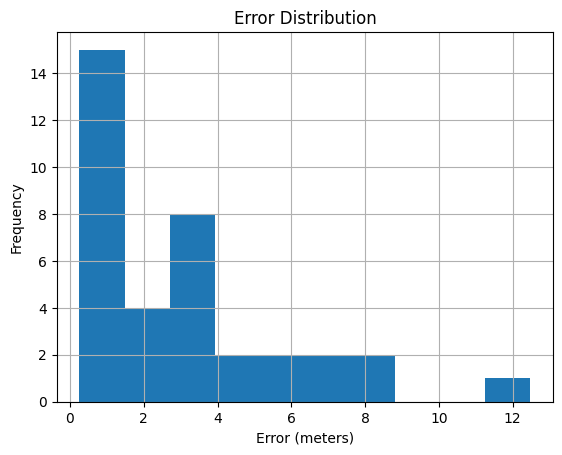

In [ ]:
plt.hist(errors, bins=10)
plt.title("Error Distribution")
plt.xlabel("Error (meters)")
plt.ylabel("Frequency")
plt.grid(True)
plt.show()